
# RetailAnalytics
### Customer Purchase Behaviour Analysis and Segmentation

## Project Overview

This project focuses on analysing customer purchase behaviour using historical transaction data from an online retail business.

The objective is to identify purchasing patterns, understand customer value and segment customers based on their shopping behaviour.

## Objectives
- Analyse customer purchasing patterns.
- Identify sales trends and product performance.
- Perform RFM analysis to understand customer value.
- Apply K-Means clustering to identify customer segments.
- Derive actionable business insights from the results.

## Tools & Technologies
Python | Pandas | NumPy | Matplotlib | Scikit-learn | Google Colab

## Dataset
UCI Online Retail Dataset (ID: 352)


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


In [2]:

!pip install ucimlrepo -q


In [3]:

from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)

df = online_retail.data.original.copy()

df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



## 1. Data Understanding and Quality Assessment

Before performing the analysis, the dataset is examined to understand its structure, identify data types and assess data quality.

This step helps determine the preprocessing requirements before conducting exploratory data analysis.



In [4]:

print(f"Total Records: {df.shape[0]:,}")
print(f"Total Features: {df.shape[1]}")

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Total Records: 541,909
Total Features: 8

Dataset Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:

df.describe(include='all').T



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

missing_data.sort_values(
    by='Missing Percentage',
    ascending=False
)


,Missing Values,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [7]:

duplicate_count = df.duplicated().sum()

print(f"Duplicate Records: {duplicate_count:,}")
print(f"Duplicate Percentage: {(duplicate_count / len(df)) * 100:.2f}%")


Duplicate Records: 5,268
Duplicate Percentage: 0.97%



## 2. Transaction Analysis and Data Preprocessing

This section investigates cancelled invoices, product returns and invalid transaction values to establish a consistent dataset for further analysis.



In [8]:

retail = df.copy()

retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'])

cancelled = retail['InvoiceNo'].str.startswith('C', na=False)

print("Cancelled Invoices:", cancelled.sum())
print("Regular Invoices:", (~cancelled).sum())

print("\nNegative Quantity Records:", (retail['Quantity'] < 0).sum())
print("Zero Quantity Records:", (retail['Quantity'] == 0).sum())

print("\nNegative Unit Prices:", (retail['UnitPrice'] < 0).sum())
print("Zero Unit Prices:", (retail['UnitPrice'] == 0).sum())


Cancelled Invoices: 9288
Regular Invoices: 532621

Negative Quantity Records: 10624
Zero Quantity Records: 0

Negative Unit Prices: 2
Zero Unit Prices: 2515


In [9]:

retail[['Quantity', 'UnitPrice']].describe()


,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [10]:

retail = retail.drop_duplicates().copy()

print(f"Records after removing duplicates: {len(retail):,}")


Records after removing duplicates: 536,641


In [11]:

sales_data = retail[
    (~retail['InvoiceNo'].str.startswith('C', na=False)) &
    (retail['Quantity'] > 0) &
    (retail['UnitPrice'] > 0)
].copy()

sales_data['Revenue'] = sales_data['Quantity'] * sales_data['UnitPrice']

print("Positive Sales Records:", f"{len(sales_data):,}")
print("Total Gross Sales: £{:,.2f}".format(sales_data['Revenue'].sum()))


Positive Sales Records: 524,878
Total Gross Sales: £10,642,110.80


In [14]:

customer_data = sales_data.dropna(subset=['CustomerID']).copy()

customer_data['CustomerID'] = customer_data['CustomerID'].astype(int)

print("Customer-Level Records:", f"{len(customer_data):,}")
print("Unique Customers:", f"{customer_data['CustomerID'].nunique():,}")
print("Missing Customer IDs:", customer_data['CustomerID'].isnull().sum())


Customer-Level Records: 392,692
Unique Customers: 4,338
Missing Customer IDs: 0


In [15]:

print("Final Dataset Shape:", customer_data.shape)

print("\nMissing Values:")
print(customer_data.isnull().sum())

print("\nDuplicate Records:", customer_data.duplicated().sum())

print("\nData Types:")
print(customer_data.dtypes)


Final Dataset Shape: (392692, 9)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

Duplicate Records: 0

Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
Revenue               float64
dtype: object



## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to identify patterns, trends and relationships within the cleaned transaction data.

The analysis focuses on sales performance, product popularity, geographical distribution and customer purchasing behaviour.


In [16]:

total_revenue = sales_data['Revenue'].sum()
total_orders = sales_data['InvoiceNo'].nunique()
total_customers = customer_data['CustomerID'].nunique()
total_products = sales_data['StockCode'].nunique()

print("RETAIL BUSINESS SUMMARY")
print("-" * 35)
print(f"Total Gross Sales: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Identifiable Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")


RETAIL BUSINESS SUMMARY
-----------------------------------
Total Gross Sales: £10,642,110.80
Total Orders: 19,960
Identifiable Customers: 4,338
Unique Products: 3,922


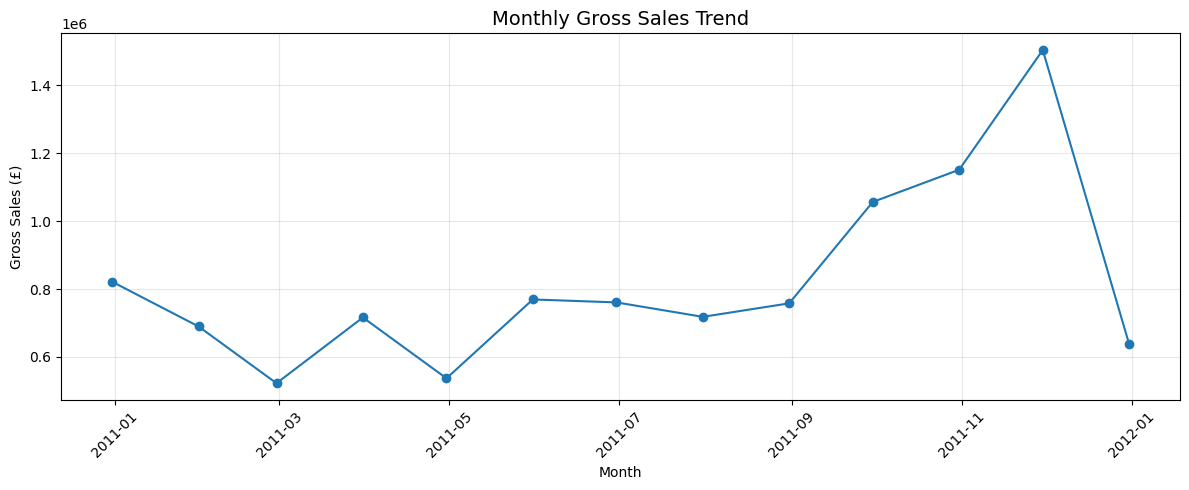

In [17]:

monthly_sales = (
    sales_data
    .set_index('InvoiceDate')
    .resample('ME')['Revenue']
    .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Monthly Gross Sales Trend', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Gross Sales (£)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


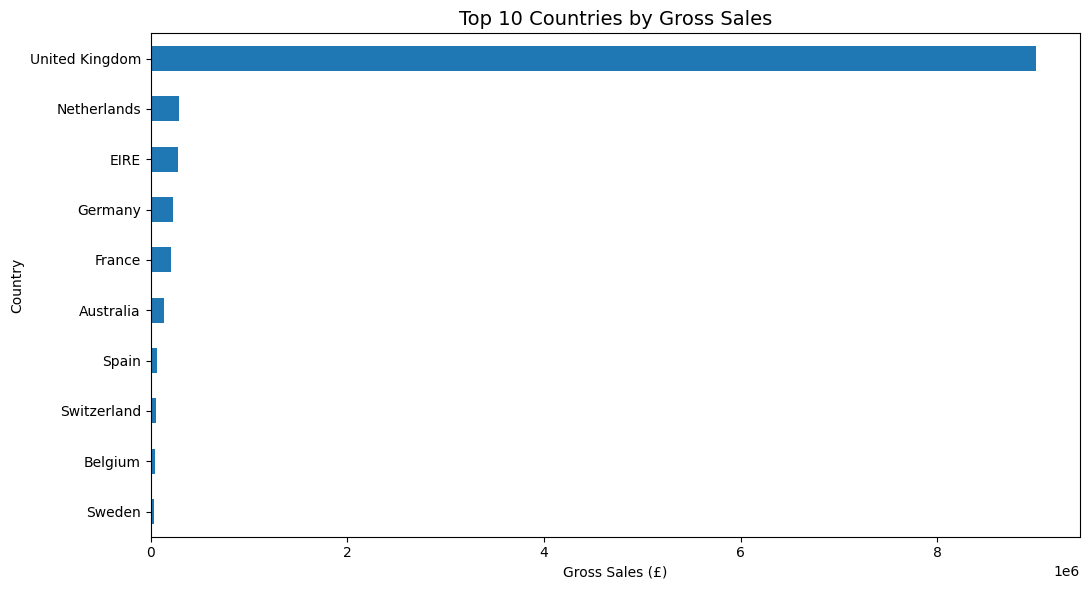

In [18]:

country_sales = (
    sales_data.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))

country_sales.sort_values().plot(kind='barh')

plt.title('Top 10 Countries by Gross Sales', fontsize=14)
plt.xlabel('Gross Sales (£)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


,Product,Quantity_Sold,Revenue
StockCode,,,
DOT,DOTCOM POSTAGE,706,206248.77
22423,REGENCY CAKESTAND 3 TIER,13851,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75
47566,PARTY BUNTING,18283,99445.23
85099B,JUMBO BAG RED RETROSPOT,48371,94159.81
23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
POST,POSTAGE,3150,78101.88
M,Manual,6984,77750.27


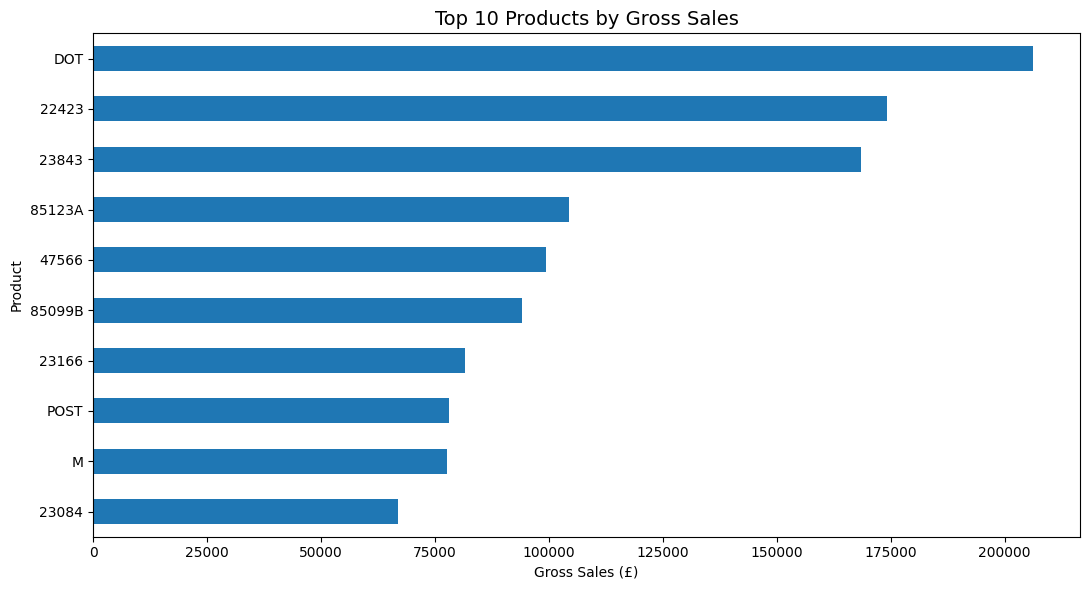

In [19]:

product_sales = (
    sales_data.groupby('StockCode')
    .agg(
        Product=('Description', 'first'),
        Quantity_Sold=('Quantity', 'sum'),
        Revenue=('Revenue', 'sum')
    )
    .sort_values('Revenue', ascending=False)
    .head(10)
)

display(product_sales)

plt.figure(figsize=(11, 6))

product_sales.sort_values('Revenue')['Revenue'].plot(kind='barh')

plt.title('Top 10 Products by Gross Sales', fontsize=14)
plt.xlabel('Gross Sales (£)')
plt.ylabel('Product')
plt.tight_layout()
plt.show()


In [20]:

print("MONTHLY SALES")
print(monthly_sales.sort_values(ascending=False).head(3))

print("\nTOP COUNTRIES")
print(country_sales.head(5))

print("\nTOP PRODUCTS")
display(product_sales.head(5))


MONTHLY SALES
InvoiceDate
2011-11-30    1503866.780
2011-10-31    1151263.730
2011-09-30    1056435.192
Name: Revenue, dtype: float64

TOP COUNTRIES
Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Name: Revenue, dtype: float64

TOP PRODUCTS


,Product,Quantity_Sold,Revenue
StockCode,,,
DOT,DOTCOM POSTAGE,706,206248.77
22423,REGENCY CAKESTAND 3 TIER,13851,174156.54
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75
47566,PARTY BUNTING,18283,99445.23



### Key EDA Observations

- November 2011 recorded the highest monthly gross sales among the observed months.
- The United Kingdom dominates the geographical revenue distribution.
- DOTCOM POSTAGE generated the highest revenue among the listed product codes.
- Regency Cakestands and Paper Craft products showed strong sales performance.

These findings highlight geographical concentration, seasonal sales patterns and differences in product revenue contribution.


In [21]:

reference_date = customer_data['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = customer_data.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
)

rfm.head()


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [22]:

print("RFM Dataset Shape:", rfm.shape)

display(rfm.describe().round(2))


RFM Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


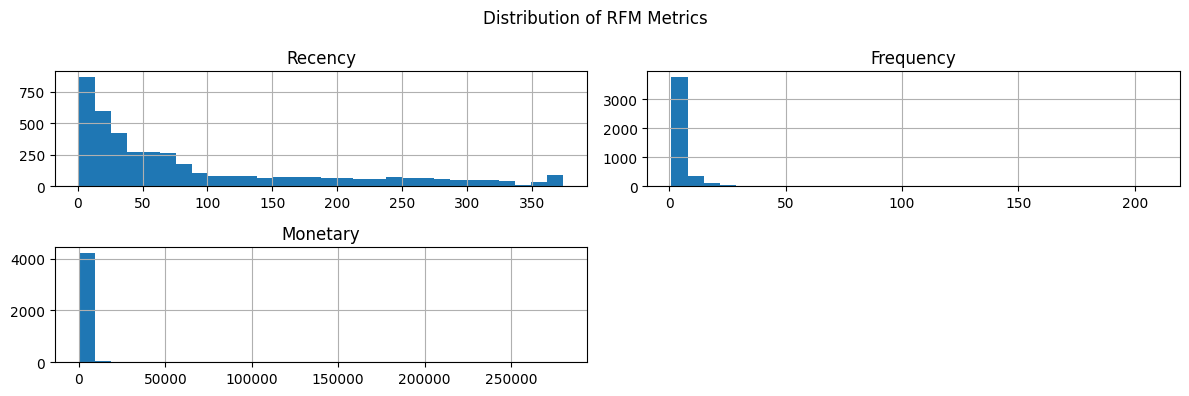

In [23]:

rfm[['Recency', 'Frequency', 'Monetary']].hist(
    bins=30, figsize=(12, 4)
)

plt.suptitle('Distribution of RFM Metrics')
plt.tight_layout()
plt.show()



## 4. Customer Segmentation using K-Means Clustering

RFM features are transformed and standardised before clustering to reduce the influence of different numerical scales and highly skewed distributions.


In [24]:

# Log transformation
rfm_log = np.log1p(rfm)

# Standardise RFM features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled RFM Data Shape:", rfm_scaled.shape)


Scaled RFM Data Shape: (4338, 3)


In [25]:

inertia = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))

results = pd.DataFrame({
    'Clusters': list(k_values),
    'Inertia': inertia,
    'Silhouette Score': silhouette_scores
})

display(results.round(3))


,Clusters,Inertia,Silhouette Score
0,2,6483.589,0.433
1,3,4869.489,0.337
2,4,3939.049,0.338
3,5,3296.709,0.316
4,6,2855.764,0.312
5,7,2548.820,0.309


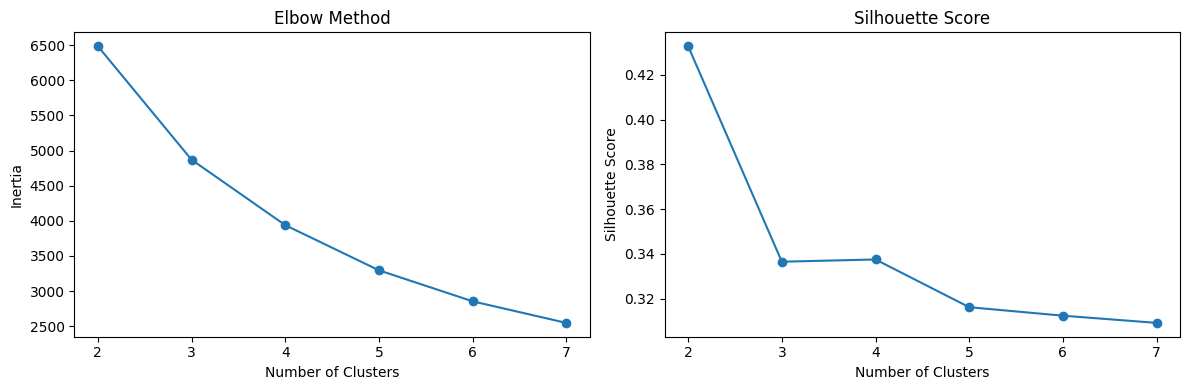

In [26]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertia, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


In [27]:

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("Final Silhouette Score:",
      round(silhouette_score(rfm_scaled, rfm['Cluster']), 3))

print("\nCustomers in Each Cluster:")
print(rfm['Cluster'].value_counts().sort_index())


Final Silhouette Score: 0.338

Customers in Each Cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


In [28]:

cluster_profile = rfm.groupby('Cluster').agg(
    Customers=('Recency', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Median_Recency=('Recency', 'median'),
    Median_Frequency=('Frequency', 'median'),
    Median_Monetary=('Monetary', 'median')
).round(2)

cluster_profile['Customer_Percentage'] = (
    cluster_profile['Customers'] / len(rfm) * 100
).round(2)

display(cluster_profile)


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percentage
Cluster,,,,,,,,
0,713,12.17,13.75,8088.02,8.0,10.0,3722.82,16.44
1,1622,181.51,1.32,341.00,174.5,1.0,296.09,37.39
2,837,17.70,2.19,557.32,17.0,2.0,480.31,19.29
3,1166,71.64,4.08,1801.78,57.0,4.0,1345.20,26.88


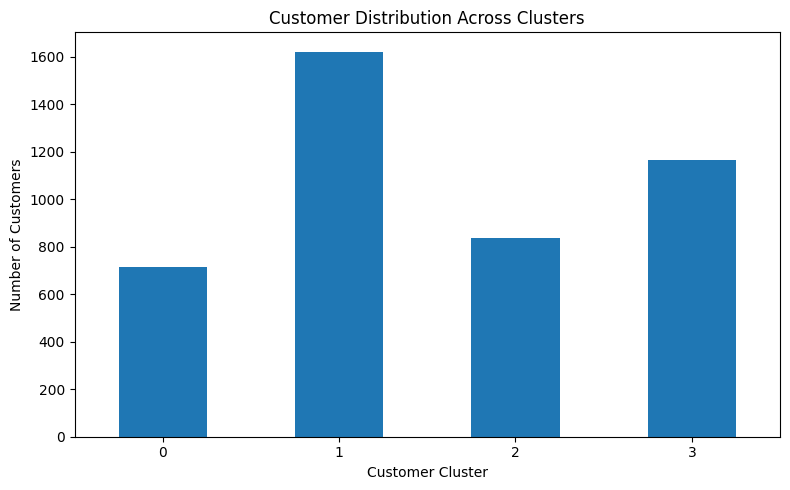

In [29]:

cluster_profile['Customers'].plot(
    kind='bar',
    figsize=(8, 5),
    rot=0
)

plt.title('Customer Distribution Across Clusters')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.tight_layout()
plt.show()


In [30]:

cluster_profile['Total_Revenue'] = rfm.groupby('Cluster')['Monetary'].sum()

cluster_profile['Revenue_Percentage'] = (
    cluster_profile['Total_Revenue'] /
    cluster_profile['Total_Revenue'].sum() * 100
).round(2)

display(cluster_profile[[
    'Customers',
    'Customer_Percentage',
    'Total_Revenue',
    'Revenue_Percentage'
]].round(2))


,Customers,Customer_Percentage,Total_Revenue,Revenue_Percentage
Cluster,,,,
0,713,16.44,5766757.07,64.89
1,1622,37.39,553099.77,6.22
2,837,19.29,466479.03,5.25
3,1166,26.88,2100873.02,23.64


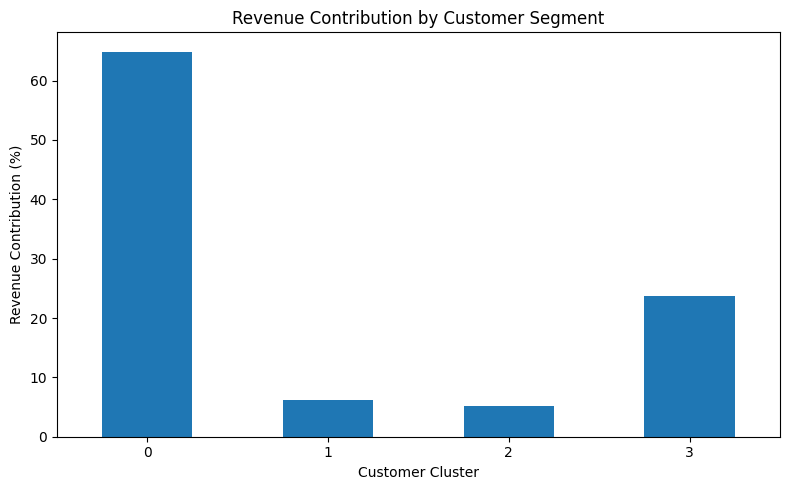

In [31]:

cluster_profile['Revenue_Percentage'].plot(
    kind='bar',
    figsize=(8, 5),
    rot=0
)

plt.title('Revenue Contribution by Customer Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Revenue Contribution (%)')
plt.tight_layout()
plt.show()



## 5. Customer Segmentation and Business Insights

The K-Means model identified four customer segments based on their RFM characteristics.

### Segment Analysis

1. High-Value Customers:
   Focus on customer retention, loyalty rewards and personalised offers.

2. Inactive Customers:
   Consider targeted re-engagement campaigns and feedback collection.

3. Recent Low-Frequency Customers:
   Encourage repeat purchases through product recommendations and introductory offers.

4. Regular Customers:
   Focus on customer engagement, loyalty programmes and cross-selling opportunities.

### Business Significance

RFM-based segmentation helps businesses understand differences in customer purchasing behaviour and develop targeted marketing strategies instead of treating all customers identically.


### Business Insights from Customer Segmentation

1. **Revenue Concentration:** High-value customers represent only 16.44% of identified customers but contribute 64.89% of their total revenue.
2. **Customer Reactivation:** Inactive customers form the largest segment, accounting for 37.39% of customers. Re-engagement campaigns may help encourage repeat purchases.
3. **Growth Opportunity:** Recent low-frequency customers have purchased recently but show limited purchase frequency. Encouraging repeat purchases could improve their long-term value.
4. **Customer Retention:** Regular customers contribute 23.64% of identified-customer revenue, making customer retention an important strategy.

Overall, the segmentation highlights differences in customer purchasing behaviour and provides a basis for developing targeted marketing and retention strategies.

## 5. Conclusion

This project analysed customer purchasing behaviour using the Online Retail dataset. After data cleaning and exploratory data analysis, RFM analysis was performed to understand customer recency, frequency, and monetary value.

K-Means clustering was applied to segment 4,338 customers into four behavioural groups: High-Value Customers, Inactive Customers, Recent Low-Frequency Customers, and Regular Customers.

The analysis revealed that high-value customers, representing only 16.44% of identified customers, contributed 64.89% of their total revenue. This highlights the importance of customer retention and targeted marketing strategies.

Overall, the project demonstrates how data analytics and machine learning can help businesses understand customer behaviour and make more informed decisions.

## 6. Limitations

1. **Missing Customer Information:** Transactions without CustomerIDs were excluded from customer segmentation.
2. **Historical Data:** The analysis is based on historical transactions and may not represent current customer behaviour.
3. **Cluster Separation:** The silhouette score indicates moderate separation between customer clusters, so some behavioural overlap may exist.
4. **Limited Features:** Segmentation uses only Recency, Frequency, and Monetary value. Other factors such as product preferences and customer demographics were not considered.
5. **No Predictive Guarantee:** The identified customer segments describe historical behaviour and do not guarantee future purchasing patterns.

## 7. Future Scope

1. Incorporate additional customer and product-related features to improve segmentation.
2. Experiment with other clustering algorithms and compare their performance.
3. Develop a dashboard to make customer insights easier to explore.
4. Build predictive models to estimate customer churn and future purchasing behaviour.
5. Evaluate targeted marketing strategies using customer segment insights.